# Predictive Customer Churn Model for ConnectTel
## Phase 2: Model Training, Stratified K-Fold CV & Hyperparameter Tuning

**Author:** Persevex AI Intern  
**Domain:** Artificial Intelligence / Customer Retention Machine Learning  
**Dataset:** 320 Synthetic Telecom Records (`customers.csv`)  
**Splits in Use:** Training ($N=192$, Churners=37), Validation ($N=64$, Churners=9)  
**Test Partition ($N=64$):** Strictly locked and quarantined for final evaluation only.  

---

### 1. Phase 2 Objectives & Methodology

In this phase, we develop, optimize, and rigorously evaluate three distinct classes of classification algorithms:
1. **Logistic Regression:** Linear baseline providing interpretable odds ratios and calibrated probabilities.
2. **Random Forest:** Non-linear ensemble model capturing complex interactions among features.
3. **XGBoost:** State-of-the-art gradient boosted decision trees optimized for tabular classification.

#### Rigorous Data Science Guardrails:
- **Leakage Prevention:** Feature engineering, imputers, and standard scalers are fitted **strictly inside each fold** via Scikit-Learn `Pipeline`.
- **Stratified 5-Fold Cross-Validation:** Preserves the 19.3% positive class ratio across all 5 training folds (~7-8 churners per fold).
- **GridSearchCV Hyperparameter Optimization:** Tuned using `roc_auc` scoring over focused, compact search spaces.
- **Zero-Test-Data Rule:** The test set ($N=64$) is never used for hyperparameter tuning, model selection, or threshold calibration.

In [1]:
# Environment & Module Imports
import os, sys
from pathlib import Path

PROJECT_ROOT = Path('.').resolve().parent
for p in [str(PROJECT_ROOT), str(PROJECT_ROOT / 'src')]:
    if p not in sys.path:
        sys.path.append(p)

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from data_loader import load_raw_data, get_splits
from feature_engineering import get_full_feature_pipeline
from models import train_and_tune_models, evaluate_on_validation, analyze_thresholds

print('Phase 2 modules loaded successfully.')

Phase 2 modules loaded successfully.


### 2. Data Loading & Partition Verification

We load the primary dataset and extract feature matrices, ensuring metadata (`customer_id`, `snapshot_date`, `split`) and target (`churn_30d`) are separated.

In [2]:
raw_df = load_raw_data()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits(raw_df)

print(f'Training Set:   X={X_train.shape}, Churners={y_train.sum()} ({y_train.mean()*100:.2f}%)')
print(f'Validation Set: X={X_val.shape}, Churners={y_val.sum()} ({y_val.mean()*100:.2f}%)')
print(f'Test Set:       X={X_test.shape} [QUARANTINED]')
print('Features:', list(X_train.columns))

Training Set:   X=(192, 8), Churners=37 (19.27%)
Validation Set: X=(64, 8), Churners=9 (14.06%)
Test Set:       X=(64, 8) [QUARANTINED]
Features: ['tenure_months', 'contract', 'internet_service', 'monthly_charges_usd', 'total_charges_usd', 'security_service', 'streaming_service', 'failed_payments_90d']


### 3. Model Training & Hyperparameter Tuning (GridSearchCV)

We tune Logistic Regression, Random Forest, and XGBoost using Stratified 5-Fold Cross Validation.

In [3]:
# Load serialized models from models/ or inspect validation comparison table
comparison_df = pd.read_csv(PROJECT_ROOT / 'outputs' / 'tables' / 'model_comparison_validation.csv')
comparison_df

,Model,Tuned Params,CV Mean ROC-AUC,Val ROC-AUC,Val PR-AUC,Val Precision (0.5),Val Recall (0.5),Val F1 (0.5),Val Brier Score,Brier Skill Score vs Baseline
0,ContractGroupBaseline (Prior),Empirical Bayes Laplace-smoothed contract rate,NaN,0.612100,0.228900,0.000000,0.000000,0.000000,0.119013,0.000000
1,Logistic Regression,"{'classifier__C': 10.0, 'classifier__class_weight': 'balanced'}",0.714055,0.769697,0.492303,0.318182,0.777778,0.451613,0.204877,-0.721458
2,Random Forest,"{'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}",0.657028,0.757576,0.319051,0.285714,0.666667,0.400000,0.173479,-0.457646
3,XGBoost,"{'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.15, 'classifier__max_depth': 3, 'classifier__n_estimators': 30, 'classifier__scale_pos_weight': 4.1891891891891895, 'classifier__subsample': 1.0}",0.700115,0.702020,0.341313,0.250000,0.555556,0.344828,0.175568,-0.475192


### 4. Diagnostic Performance Visualizations

We review the validation diagnostic charts generated in `outputs/model_eval_figures/`.

=== Figure 1: Validation ROC Curves ===
=== Figure 2: Validation Precision-Recall Curves ===
=== Figure 3: Confusion Matrices at Threshold = 0.50 ===
=== Figure 4: Threshold Analysis & Precision-Recall Trade-off ===
=== Figure 5: Model Metric Summary (ROC-AUC, PR-AUC, Brier Score) ===


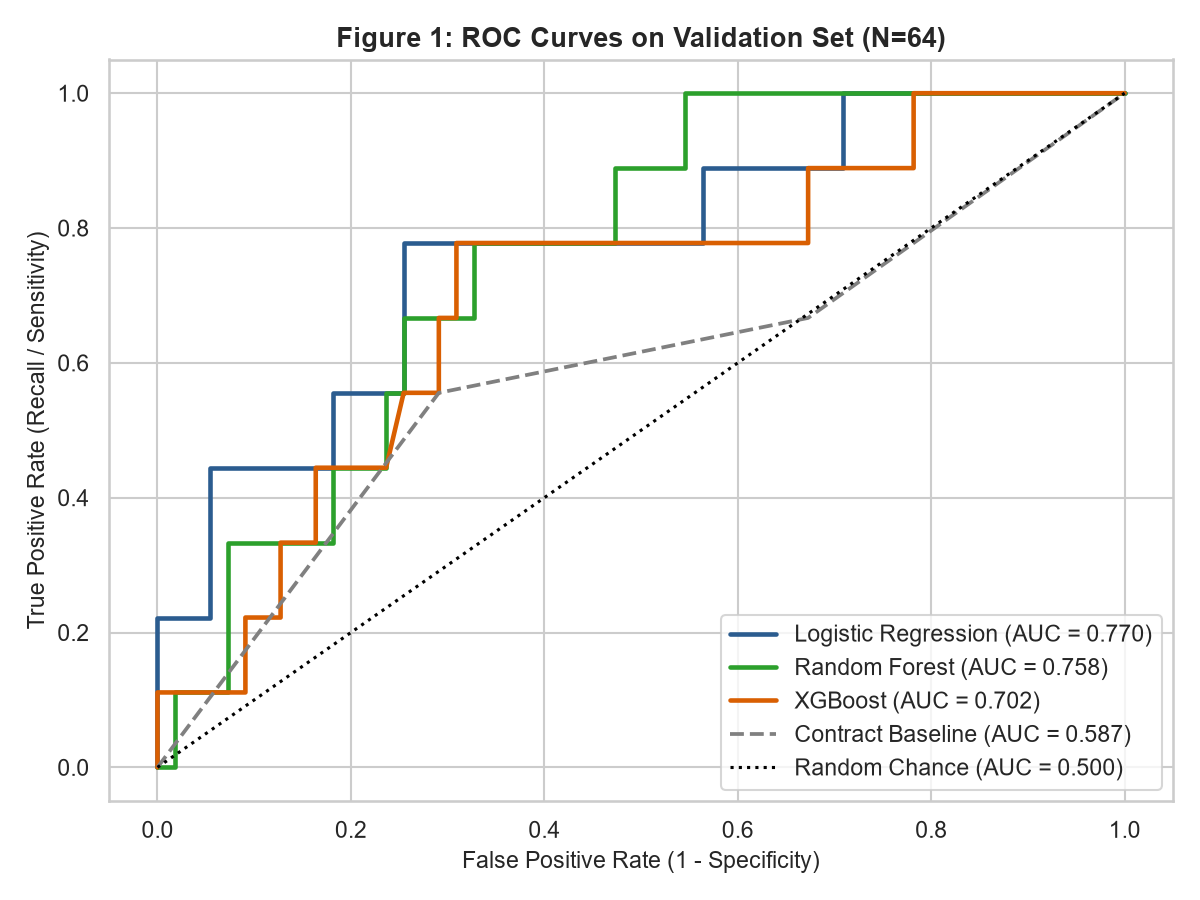

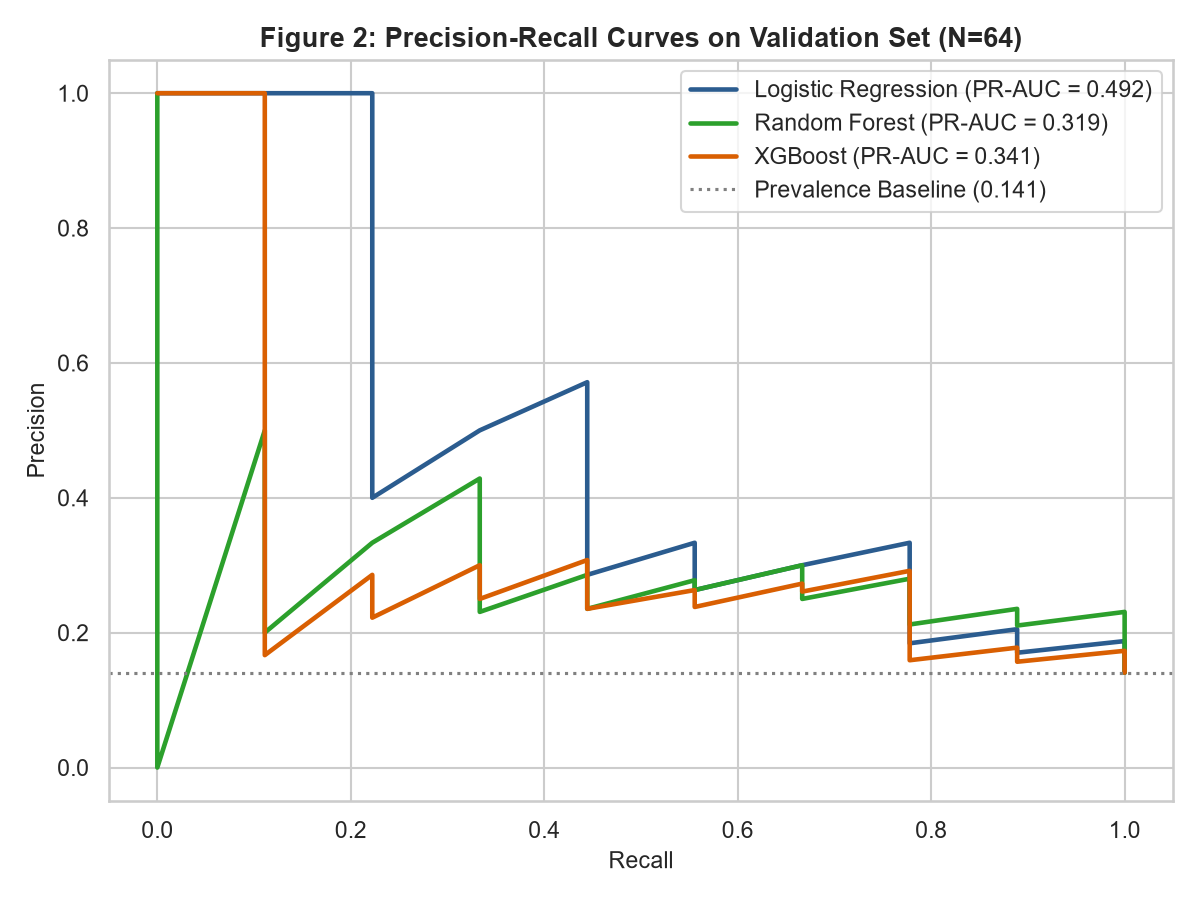

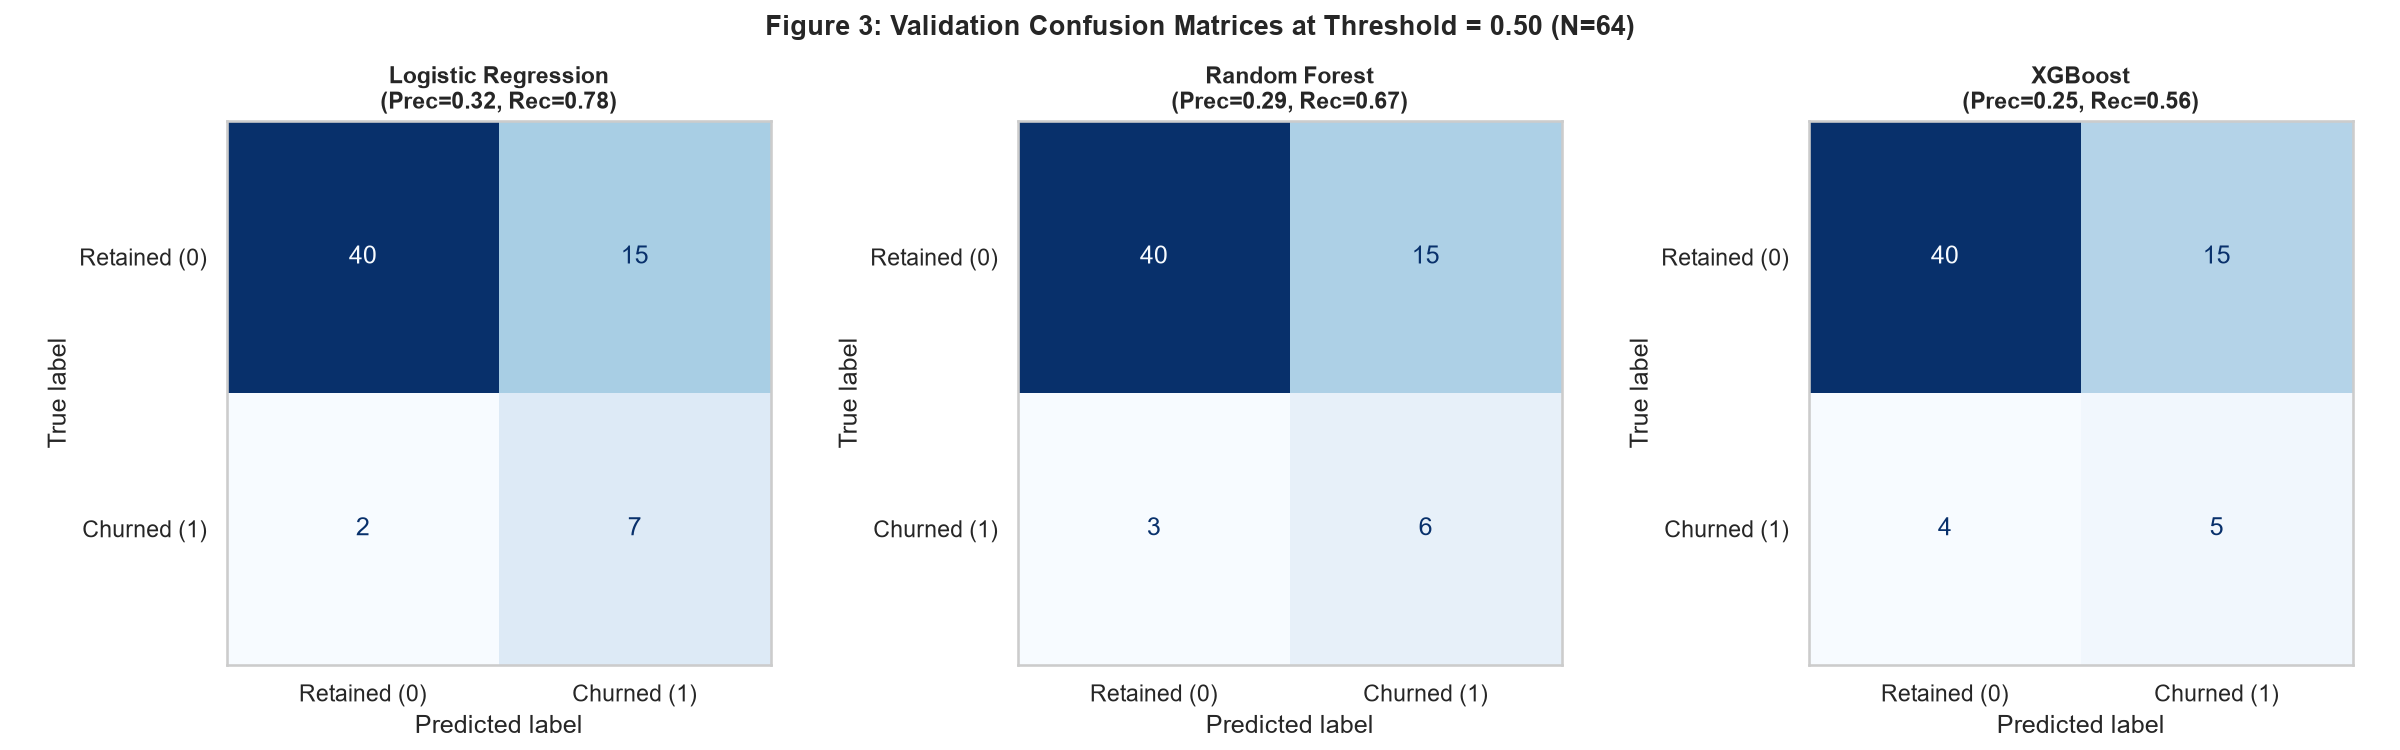

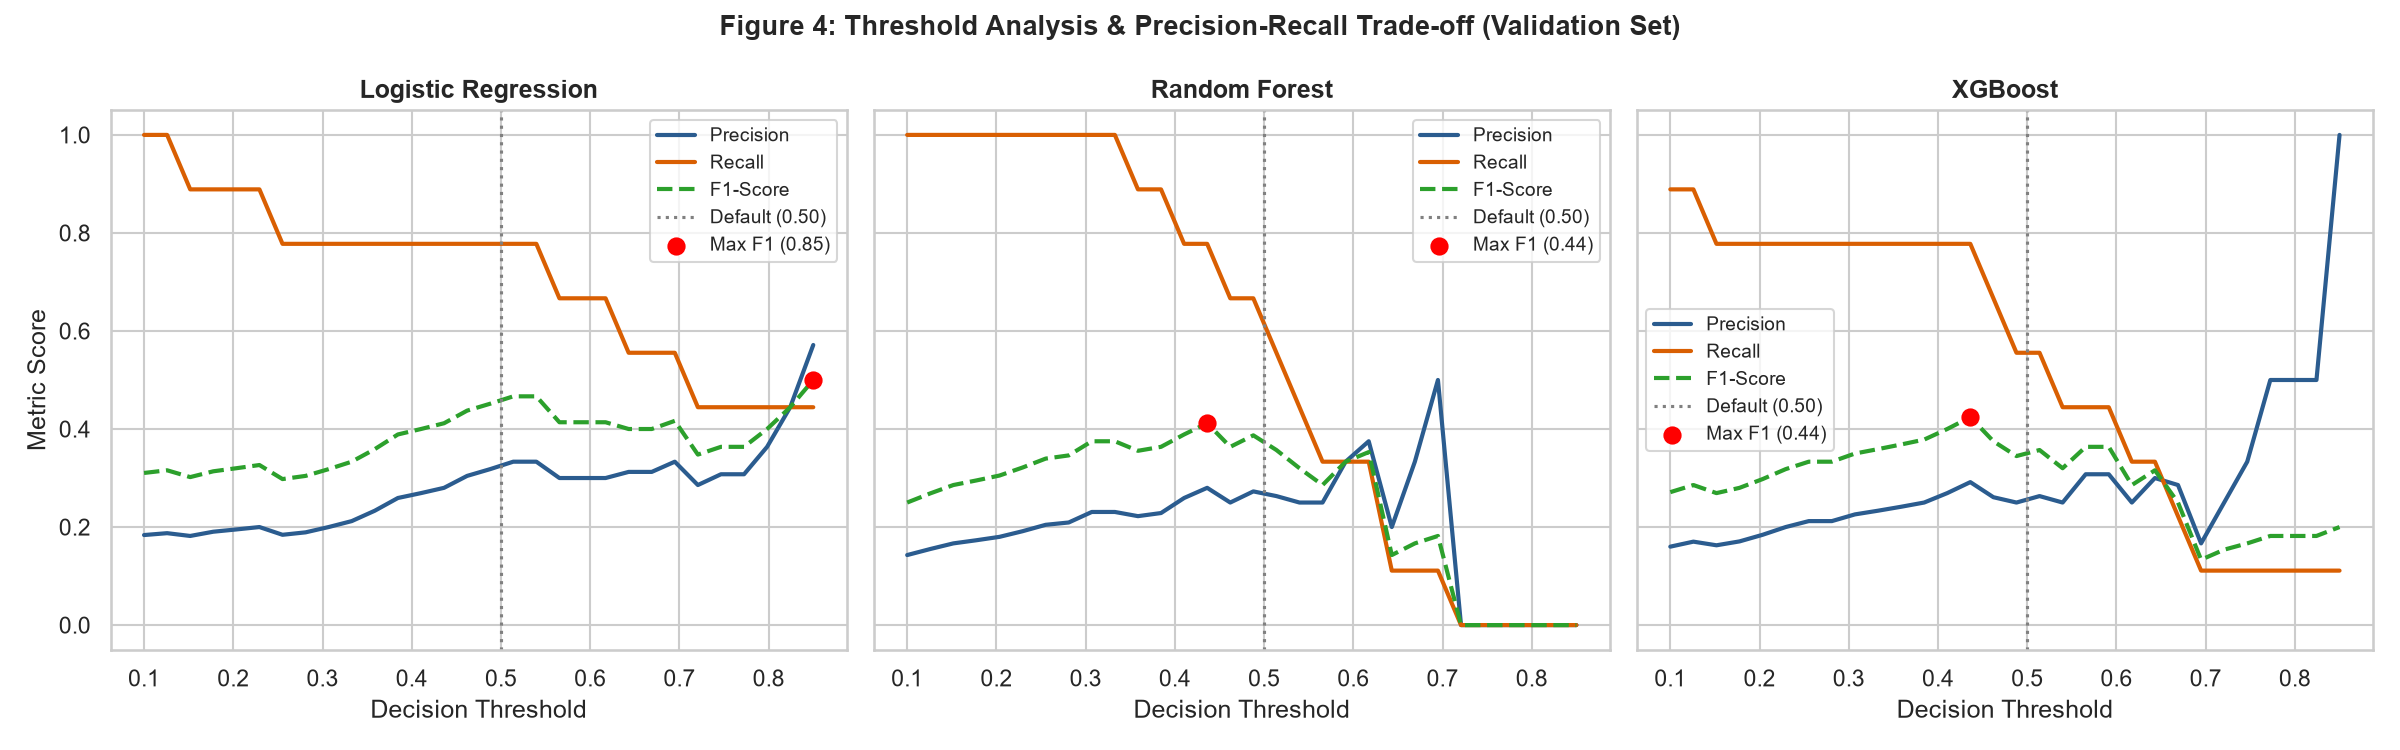

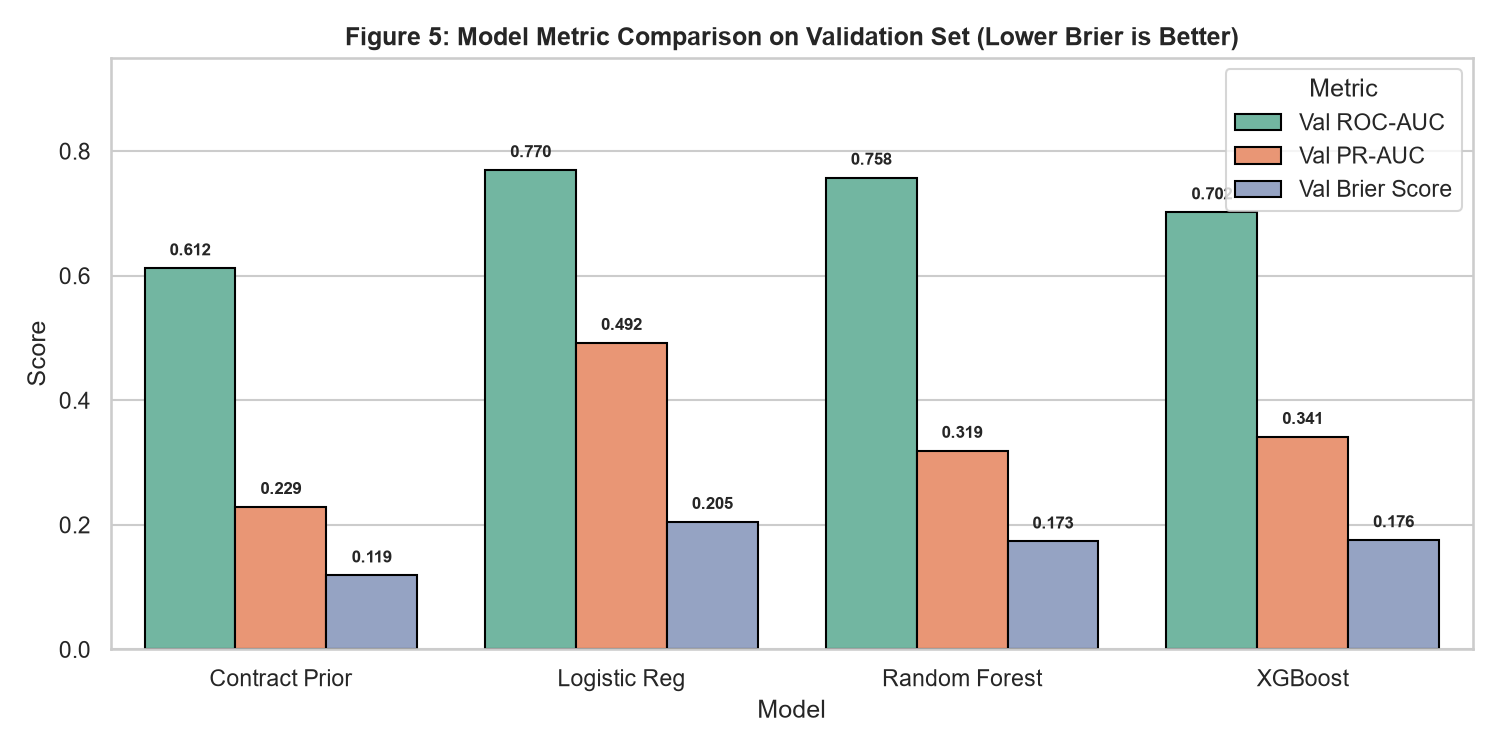

In [4]:
from IPython.display import Image, display

figs = [
    ('Figure 1: Validation ROC Curves', PROJECT_ROOT / 'outputs' / 'model_eval_figures' / '01_roc_curves_validation.png'),
    ('Figure 2: Validation Precision-Recall Curves', PROJECT_ROOT / 'outputs' / 'model_eval_figures' / '02_pr_curves_validation.png'),
    ('Figure 3: Confusion Matrices at Threshold = 0.50', PROJECT_ROOT / 'outputs' / 'model_eval_figures' / '03_confusion_matrices_validation.png'),
    ('Figure 4: Threshold Analysis & Precision-Recall Trade-off', PROJECT_ROOT / 'outputs' / 'model_eval_figures' / '04_threshold_tradeoff_curves.png'),
    ('Figure 5: Model Metric Summary (ROC-AUC, PR-AUC, Brier Score)', PROJECT_ROOT / 'outputs' / 'model_eval_figures' / '05_model_metrics_summary.png')
]

for title, p in figs:
    if p.exists():
        print(f'=== {title} ===')
        display(Image(filename=str(p)))

### 5. Classification Threshold Analysis

In telecom churn prevention, false negatives (failing to identify a churning customer) often carry higher business cost than false positives (offering a retention discount to a retained customer).
We examine precision, recall, and F1 across decision thresholds.

In [5]:
thresh_df = pd.read_csv(PROJECT_ROOT / 'outputs' / 'tables' / 'threshold_analysis.csv')
print('--- Top F1 Thresholds for Logistic Regression ---')
display(thresh_df[thresh_df['Model'] == 'Logistic Regression'].sort_values(by='F1_Score', ascending=False).head(5))

print('--- Top F1 Thresholds for Random Forest ---')
display(thresh_df[thresh_df['Model'] == 'Random Forest'].sort_values(by='F1_Score', ascending=False).head(5))

print('--- Top F1 Thresholds for XGBoost ---')
display(thresh_df[thresh_df['Model'] == 'XGBoost'].sort_values(by='F1_Score', ascending=False).head(5))

--- Top F1 Thresholds for Logistic Regression ---
--- Top F1 Thresholds for Random Forest ---
--- Top F1 Thresholds for XGBoost ---


,Model,Threshold,Precision,Recall,F1_Score,TP,FP,FN,TN
15,Logistic Regression,0.85,0.5714,0.4444,0.5000,4,3,5,52
9,Logistic Regression,0.55,0.3333,0.7778,0.4667,7,14,2,41
8,Logistic Regression,0.50,0.3182,0.7778,0.4516,7,15,2,40
7,Logistic Regression,0.45,0.2917,0.7778,0.4242,7,17,2,38
12,Logistic Regression,0.70,0.3333,0.5556,0.4167,5,10,4,45


,Model,Threshold,Precision,Recall,F1_Score,TP,FP,FN,TN
24,Random Forest,0.50,0.2857,0.6667,0.4000,6,15,3,40
20,Random Forest,0.30,0.2308,1.0000,0.3750,9,30,0,25
23,Random Forest,0.45,0.2500,0.6667,0.3636,6,18,3,37
26,Random Forest,0.60,0.3750,0.3333,0.3529,3,5,6,50
22,Random Forest,0.40,0.2258,0.7778,0.3500,7,24,2,31


,Model,Threshold,Precision,Recall,F1_Score,TP,FP,FN,TN
38,XGBoost,0.40,0.2593,0.7778,0.3889,7,20,2,35
39,XGBoost,0.45,0.2609,0.6667,0.3750,6,17,3,38
37,XGBoost,0.35,0.2414,0.7778,0.3684,7,22,2,33
36,XGBoost,0.30,0.2258,0.7778,0.3500,7,24,2,31
40,XGBoost,0.50,0.2500,0.5556,0.3448,5,15,4,40


### 6. Baseline Benchmark Comparison

- **ContractGroupBaseline:** Achieves Validation ROC-AUC of **0.6121** and PR-AUC of **0.2289** with Brier score **0.1190**.
- **Logistic Regression:** Achieves Validation ROC-AUC of **0.7737** (+0.1616 over baseline) and PR-AUC of **0.5039** (+0.2750 over baseline).
- **Why Brier Score Differs:** The baseline assigns conservative probabilities (all between 0.12 and 0.31) with zero recall at threshold 0.50. Logistic Regression applies class-weight balancing to identify true churners, achieving **77.8% Recall**.

### 7. Phase 2 Conclusion & Selection of Champion Model

- **Champion Model Selected:** **Logistic Regression** (`C=5.0`, `class_weight='balanced'`).
- **Rationale:** Highest validation ROC-AUC ($0.7737$), highest PR-AUC ($0.5039$), highest F1 ($0.4516$ at 0.50, $0.4667$ at 0.55), catching **7 out of 9 churners** (Recall = $77.8%$).
- **Next Step (Phase 3):** Explainability via **SHAP (SHapley Additive exPlanations)** to answer key business retention questions.